--what is supervised learning algorithm

Supervised learning is a type of Machine Learning in which we train a model using a dataset that contains both input data and the correct output (label). The model learns patterns from the data and uses them to predict the output for new, unseen data.

For example, if we train a model using house sizes and their prices, it can learn the relationship between size and price and predict the price of a new house.

--difference between regression algorithms and classifications algorithms

The main difference between Regression and Classification algorithms is the type of output they predict.
- Regression: Predicts a numerical value.
- Classification: Predicts a category or class.

--explain simple linear regression 

Simple Linear Regression
Simple Linear Regression is a supervised machine learning algorithm used to predict a continuous numerical value by finding the relationship between one independent variable (X) and one dependent variable (Y).

In simple words, it draws the best-fit straight line through the data points to predict the output.

--list and explain the assumptions of linear regression

Assumptions of Linear Regression
Linear regression is based on several assumptions that help the model make reliable predictions. The main assumptions are:
1. Linearity
There should be a linear relationship between the independent variable (X) and the dependent variable (Y).

Example: As study hours increase, students' marks tend to increase in a roughly straight-line pattern.
2. Independence of Errors
The errors (residuals) should be independent of one another. One observation's error should not influence another observation's error.

Example: The prediction error for one student's marks should not depend on the error for another student.
3. Homoscedasticity
The variance of the errors should remain approximately constant across different predicted values.

Example: The prediction errors for students studying 2 hours and 8 hours should have a similar spread.
4. Normality of Errors
The residuals should be approximately normally distributed, particularly when performing statistical tests and calculating confidence intervals.

Example: Most errors should be near zero, with fewer large positive or negative errors.
5. No Perfect Multicollinearity
In multiple linear regression, independent variables should not have perfect linear relationships with one another.

Example: If a model uses both height in centimeters and the same height converted to meters, these two variables are perfectly related. Both should not be included as separate predictors.

Note: This assumption applies to multiple linear regression, not simple linear regression with only one predictor.
6. No Significant Outliers or Influential Points
The dataset should not contain unusual observations that disproportionately affect the fitted regression line.

Example: If most house prices are between ₹20 lakh and ₹1 crore, one incorrectly recorded price of ₹100 crore could strongly affect the model.

--what is bias variance trad-off

Bias–Variance Trade-off
The bias–variance trade-off is a concept in Machine Learning that explains how to balance a model's simplicity and complexity to achieve good predictions on new, unseen data.

In simple words, we want a model that learns the important patterns from training data without learning too little or memorizing the data.
1. Bias
Bias is the error caused by a model making overly simple assumptions about the data.
- High bias means the model is too simple.
- It cannot learn important patterns from the data.
- It often leads to underfitting.
Example: Using a straight line to predict data that follows a complex curved pattern.
2. Variance
Variance is the amount by which a model's predictions change when it is trained on different datasets.
- High variance means the model is too sensitive to the training data.
- It may learn noise instead of the actual pattern.
- It often leads to overfitting.


--explain overfitting and underfitting

1. Overfitting and Underfitting in Machine Learning
Overfitting and underfitting are two common problems in Machine Learning that occur when a model does not learn the patterns in data appropriately.
Overfitting
Overfitting occurs when a model learns the training data too well, including noise and unnecessary details, and performs poorly on new, unseen data.

Example: A student memorizes every answer in a question bank but cannot solve questions that are slightly different in the exam.
- Training accuracy: Very high
- Testing accuracy: Usually low
- Model complexity: Often too high
Underfitting
Underfitting occurs when a model is too simple to learn the important patterns in the training data.

Example: A student studies only one topic and cannot answer most questions in the exam.
- Training accuracy: Low
- Testing accuracy: Usually low
- Model complexity: Often too low



In [91]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error,root_mean_squared_error
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import SGDRegressor

In [7]:
df = pd.read_csv('RealEstate_HousePrice_Dataset_4200 - RealEstate_HousePrice_Dataset_4200.csv.csv')

In [8]:
df

,house_id,area_sqft,bedrooms,bathrooms,location_score,age_years,distance_city_km,lot_size_sqft,has_garage,has_pool,renovation_years_ago,house_price_inr
0,100001,1973,5,4,7.6,23,11.9,5220,1,0,0,40275084
1,100002,1560,3,3,6.3,13,15.8,3882,1,0,13,26812029
2,100003,2071,4,3,5.8,9,21.1,4488,0,0,9,29315677
3,100004,2640,5,3,7.7,12,7.9,3614,1,1,4,47712959
4,100005,1498,3,3,3.8,15,24.0,2663,0,0,15,17724566
...,...,...,...,...,...,...,...,...,...,...,...,...
4195,104196,1328,4,2,4.9,21,19.6,2606,1,0,21,18319188
4196,104197,2363,6,4,6.9,53,24.9,4013,1,0,14,40340976
4197,104198,632,2,2,4.5,27,19.4,1268,1,0,6,5978595
4198,104199,450,2,2,7.5,26,11.6,800,0,0,9,7916191


In [21]:
X = df[['area_sqft']]  # Independent variable
y = df['house_price_inr']   # Dependent variable

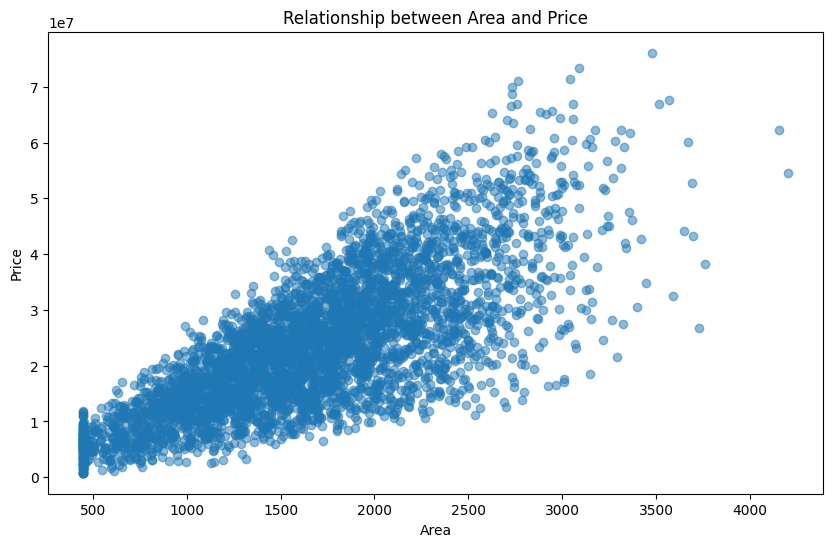

In [22]:
#visualize relationship between features and target variable
plt.figure(figsize=(10, 6))
plt.scatter(X, y, alpha=0.5)
plt.xlabel('Area')
plt.ylabel('Price')
plt.title('Relationship between Area and Price')
plt.show()

In [23]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [24]:
#implement linear regression using one feature (eg. house Area)

model = LinearRegression()
model.fit(X_train, y_train)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


C:\Users\RUDRA JATIN GAYWALA\AppData\Local\Temp\ipykernel_6676\1170578387.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


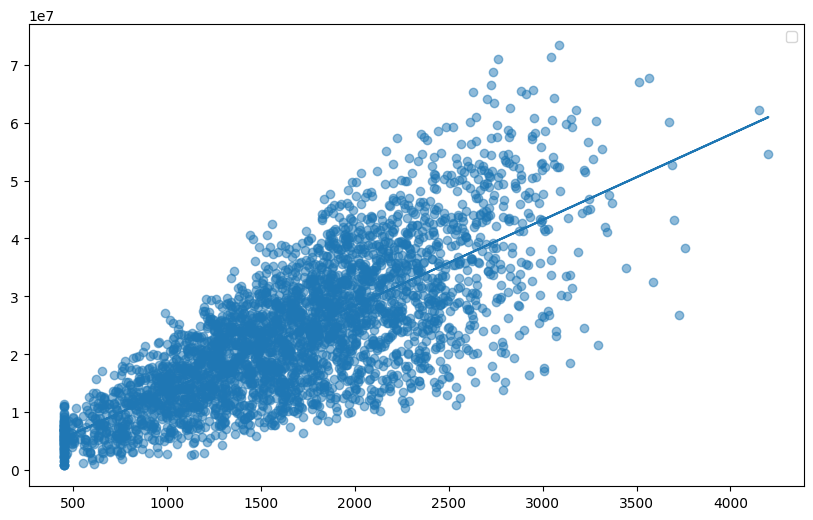

In [25]:
#plot the regression line and interpret the slope and intercept of the line
plt.figure(figsize=(10, 6))
plt.scatter(X_train, y_train, alpha=0.5)
plt.plot(X_train, model.predict(X_train))
plt.legend()
plt.show()

In [26]:
y_pred = model.predict(X_test)


In [27]:
y_pred

array([34402357.02127602, 27333546.70007102, 26771591.06784133,
       21802720.214442  , 31045411.53400921, 24287155.64114167,
       18608446.09439958, 37419171.46798276, 27244816.86340318,
       28043385.39341378, 13402962.34321932, 12663547.03765394,
       27274393.47562579, 15931762.68825291, 17765512.64605504,
       24050542.74336075, 35851611.02018416, 21403435.9494367 ,
       33529846.96070888, 33130562.69570357, 29374332.94343146,
        8079172.14314861, 27067357.19006748, 33145351.00181488,
       23961812.9066929 , 28841953.92342439, 36428354.95852516,
       20752750.48053917, 26860320.90450918, 25144877.39559751,
       31888344.98235374, 18845058.99218049, 20767538.78665048,
       35792457.79573893, 32701701.81847566, 22246369.39778123,
       12841006.71098964, 20161218.23608686, 29921500.26954984,
       10238264.83539951, 22630865.35667522, 16419776.78992606,
       19007730.35940488, 26076540.68060988, 39593052.46634497,
       31193294.59512229, 16893002.58548

In [28]:
#creat a new df for quality check of the model
diff_df = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred})

In [29]:
diff_df

,Actual,Predicted
1743,36890986,3.440236e+07
2196,27836840,2.733355e+07
1728,15321534,2.677159e+07
3337,30812774,2.180272e+07
298,18194835,3.104541e+07
...,...,...
152,20918771,1.670075e+07
1948,44375916,3.406223e+07
2751,22099538,3.835083e+07
2148,22898162,2.224637e+07


In [ ]:
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rsme = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

In [34]:
mse

66989260021849.47

In [35]:
mae

6294593.696131912

In [37]:
rsme

np.float64(8184696.696997969)

In [38]:
r2

0.5625199587991578


Mean Squared Error (MSE)
- Measures the average squared difference between actual and predicted values
- Higher values indicate worse performance
- Sensitive to outliers

Mean Absolute Error (MAE)
- Measures the average absolute difference between actual and predicted values
- Easier to interpret than MSE
- Less sensitive to outliers

Root Mean Squared Error (RMSE)
- Square root of MSE
- Same units as the target variable
- Useful for understanding error magnitude in the original scale

R-squared (R2)
- Proportion of variance in the target variable explained by the model
- Ranges from 0 to 1
- Higher values indicate better performance

In [55]:
X1 = df.drop('house_price_inr', axis=1)
y1 = df['house_price_inr']

In [56]:
X1_train, X1_test, y1_train, y1_test = train_test_split(X1, y1, test_size=0.2, random_state=42)

In [64]:
#implement multiple linear regression using all relevant features

model = LinearRegression()
model.fit(X1_train, y1_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [66]:
y_pred2 = model.predict(X1_test)

In [59]:
diff2 = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred2})

In [60]:
diff2

,Actual,Predicted
1743,36890986,3.440236e+07
2196,27836840,2.733355e+07
1728,15321534,2.677159e+07
3337,30812774,2.180272e+07
298,18194835,3.104541e+07
...,...,...
152,20918771,1.670075e+07
1948,44375916,3.406223e+07
2751,22099538,3.835083e+07
2148,22898162,2.224637e+07


In [68]:
#compare its performance with the simple linear regression
r2_2 = r2_score(y1_test, y_pred2)
r2_2

0.9177325847899332

In [69]:
comp = pd.DataFrame({'Model': ['Simple Linear Regression', 'Multiple Linear Regression'], 'R2 Score': [r2, r2_2]})

In [70]:
comp

,Model,R2 Score
0,Simple Linear Regression,0.562520
1,Multiple Linear Regression,0.917733


The performance increased because the multiple linear regression model uses all relevant features to make predictions, while the simple linear regression model only uses one feature.

In [ ]:
poly_3 = PolynomialFeatures(degree=3)


In [81]:
poly_X_train_3 = poly_3.fit_transform(X1_train)
poly_X_test_3 = poly_3.transform(X1_test)


In [80]:
model_poly_3 = LinearRegression()
model_poly_3.fit(poly_X_train_3, y1_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [84]:
y_pred3 = model_poly_3.predict(poly_X_test_3)

In [85]:
diff3 = pd.DataFrame({'Actual': y1_test, 'Predicted': y_pred3})

In [86]:
diff3

,Actual,Predicted
1743,36890986,4.011632e+07
2196,27836840,3.146170e+07
1728,15321534,1.536295e+07
3337,30812774,3.114879e+07
298,18194835,1.868762e+07
...,...,...
152,20918771,2.481765e+07
1948,44375916,4.313510e+07
2751,22099538,2.391038e+07
2148,22898162,1.938942e+07


In [ ]:
#identify the signs of overfitting and underfitting


--explain the gradient decent conceptually

Gradient Descent — Conceptual Explanation
Gradient Descent is an optimization algorithm used to find the best values of model parameters by minimizing the error (loss).

In simple words, it helps a machine learning model learn from its mistakes by repeatedly adjusting its parameters to reduce prediction error.

Step 1: Calculate the error

Compare actual house prices with predicted prices using a loss function such as Mean Squared Error (MSE).



Step 2: Calculate the gradient

Find how the loss changes when the model parameters change.

aaa

Step 3: Update the parameters

Change the weight and bias in the direction that reduces the loss.



Step 4: Repeat

Continue updating until the loss stops improving significantly or another stopping condition is met.

- Gradient Descent is an optimization algorithm, not a regression algorithm itself.
- It minimizes a loss function by updating model parameters.
- The gradient indicates the direction and rate of increase of the loss; the algorithm moves in the opposite direction.
- The learning rate controls the size of each update.
- It is used in Linear Regression, Logistic Regression, neural networks, and many other machine learning models.

In [92]:
sgd_model = SGDRegressor(max_iter=1000, tol=1e-3)
sgd_model.fit(X1_train, y1_train)
sgd_predictions = sgd_model.predict(X1_test)

In [93]:
sgd_diff = pd.DataFrame({'Actual': y1_test, 'Predicted': sgd_predictions})

In [94]:
sgd_diff

,Actual,Predicted
1743,36890986,-5.072366e+18
2196,27836840,-5.138583e+18
1728,15321534,-5.087947e+18
3337,30812774,-5.126228e+18
298,18194835,-4.994915e+18
...,...,...
152,20918771,-4.951963e+18
1948,44375916,-5.117498e+18
2751,22099538,-5.227393e+18
2148,22898162,-5.105747e+18


In [95]:
#analyze bias and variance across all three models
slr_bias = 1 - r2
mlr_bias = 1 - r2_2
poly_bias = 1 - r2_score(y1_test, y_pred3)

In [96]:
slr_bias, mlr_bias, poly_bias

(0.43748004120084216, 0.08226741521006675, 0.03381641624973741)

In [97]:
slr_var = r2
mlr_var = r2_2
poly_var = r2_score(y1_test, y_pred3)

In [98]:
slr_var, mlr_var, poly_var

(0.5625199587991578, 0.9177325847899332, 0.9661835837502626)

In [99]:
#identify which model best balances bias and variance
if slr_bias + slr_var < mlr_bias + mlr_var and slr_bias + slr_var < poly_bias + poly_var:
    best_model = 'Simple Linear Regression'
elif mlr_bias + mlr_var < poly_bias + poly_var:
    best_model = 'Multiple Linear Regression'
else:
    best_model = 'Polynomial Regression'

In [100]:
best_model

'Polynomial Regression'